
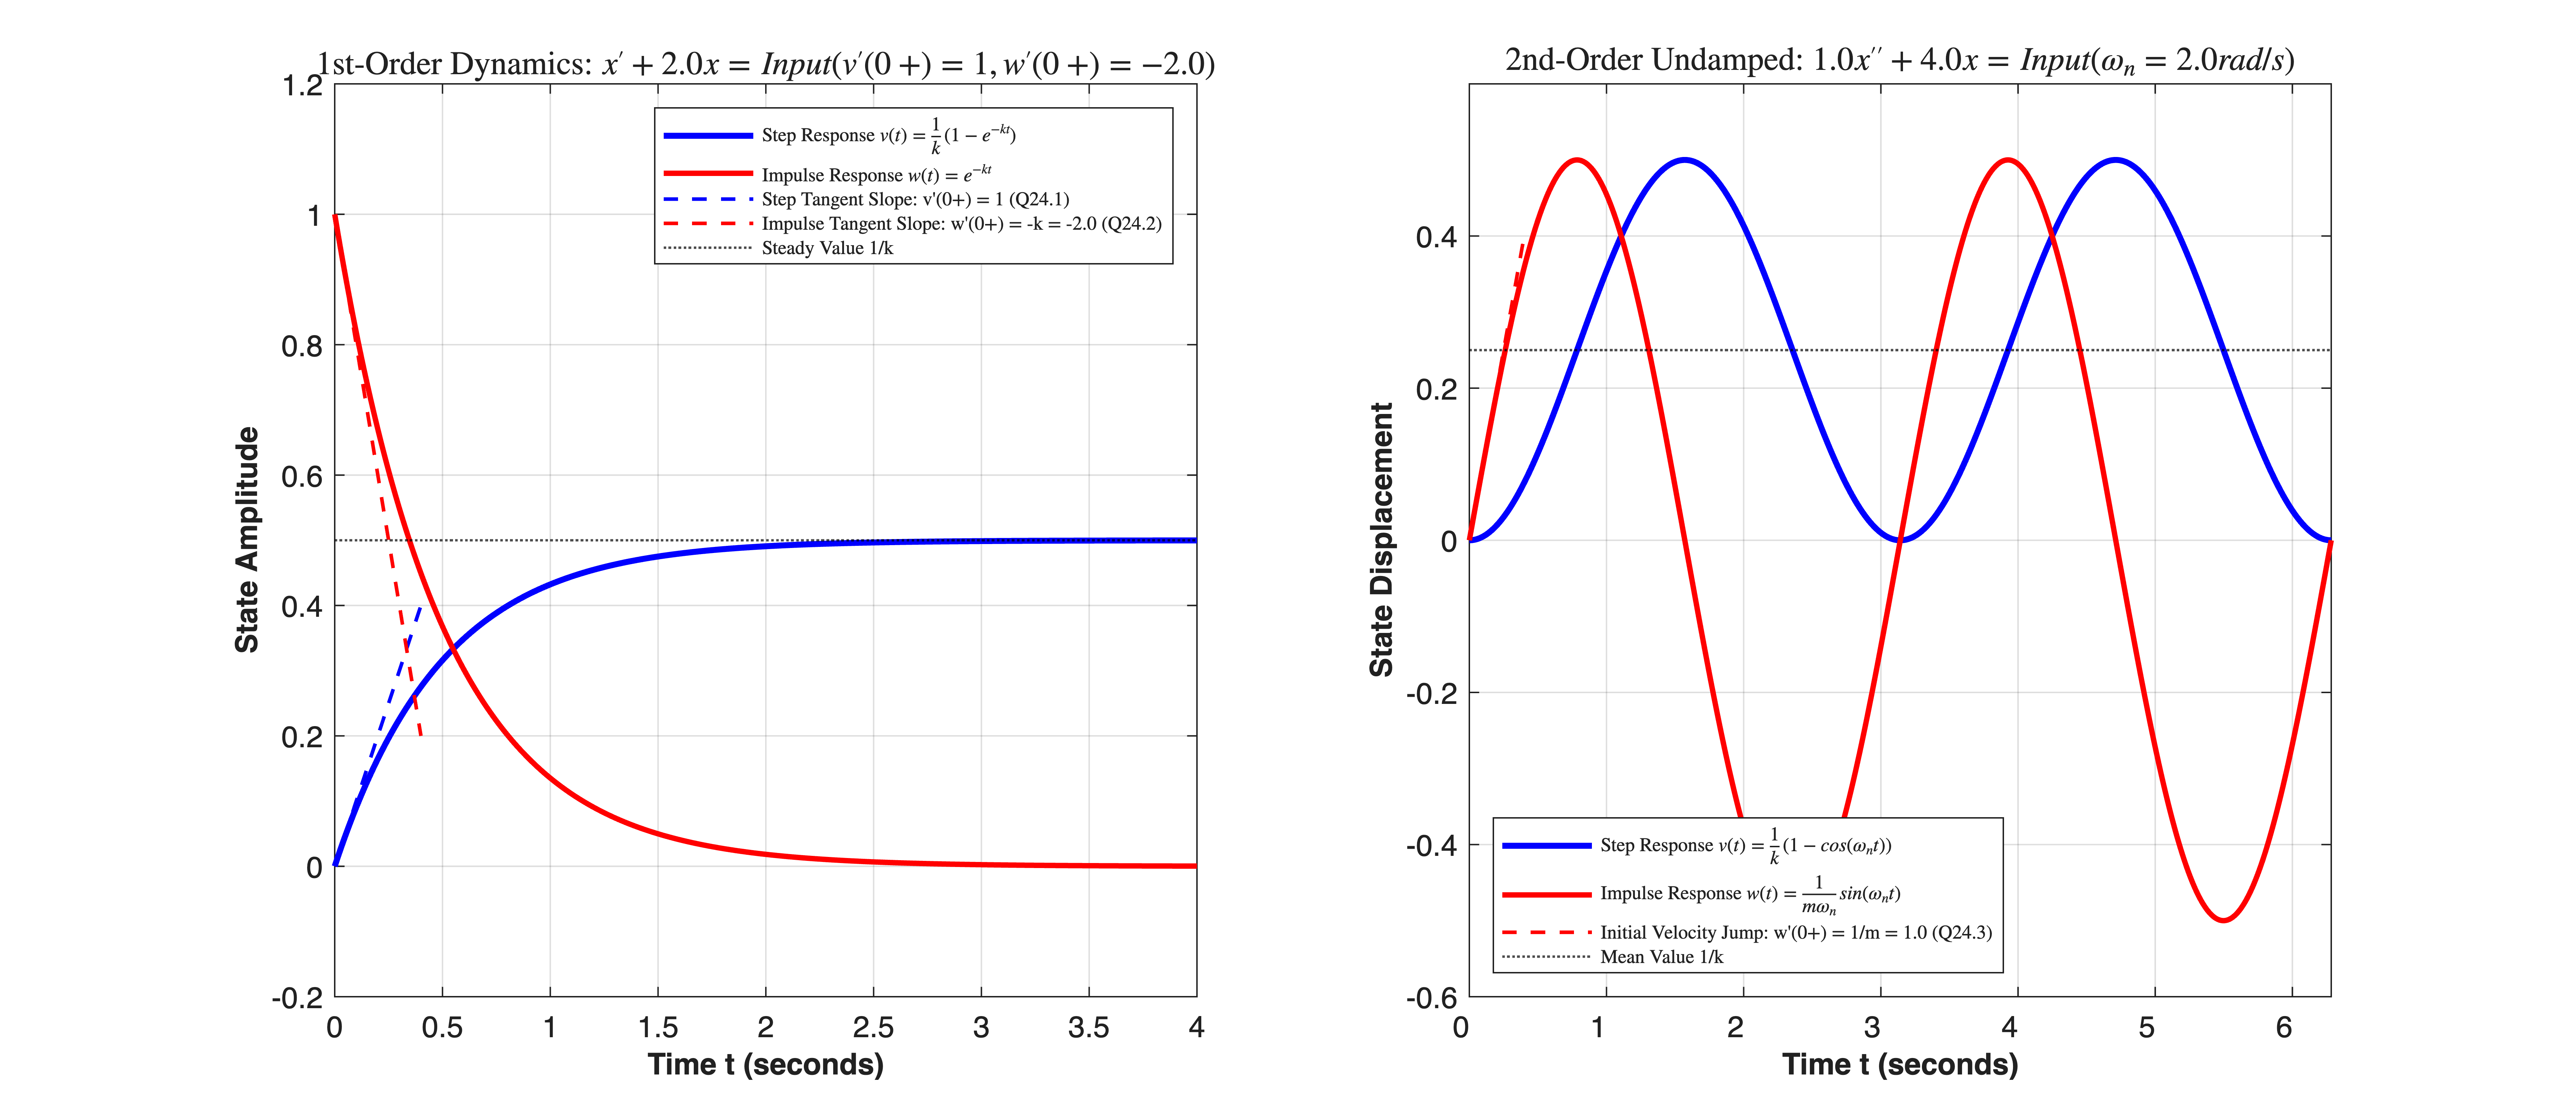

In [1]:
%% MIT 18.03 Lecture 24: Unit Impulse & Step Responses (1st & 2nd Order)
% Description: Simulates dynamic responses under singularity inputs via Control System Toolbox:
%              1) 1st-order system: x' + k*x = u(t) (Step) and x' + k*x = delta(t) (Impulse).
%              2) 2nd-order system: m*x'' + k*x = u(t) and m*x'' + k*x = delta(t).
%              3) Numerical verification of initial velocity and state jumps at t = 0+.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, step, impulse, pole).
%
% % MBD Concept Mapping: Demonstrates fundamental test inputs: Step v(t) for tracking metrics,
% %                      and Impulse w(t) as the transfer function kernel h(t) = L^-1{G(s)}.
% %                      Validates equivalent initial value conversion: m*Delta(v) = Impulse.


clear; clc; close all;


%% =========================================================================
%% Part 1: First-Order Plant Dynamics (Lecture Section [3])
%% =========================================================================
% Equation: x' + k*x = q(t) -> G1(s) = 1 / (s + k)
k_1st = 2.0; % Decay rate constant
G1 = tf(1, [1, k_1st]);


t_eval_1 = linspace(0, 4.0, 800);


% Control System Toolbox evaluation
[v1_step, ~]    = step(G1, t_eval_1);    % v(t) = (1/k)*(1 - exp(-k*t))
[w1_impulse, ~] = impulse(G1, t_eval_1); % w(t) = exp(-k*t)


% Theoretical Initial Slopes at t = 0+
v1_dot_0plus = 1.0;         % Q24.1: v'(0+) = 1
w1_dot_0plus = -k_1st;      % Q24.2: w'(0+) = -k


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 500]);


% Subplot 1: 1st-Order Step vs. Impulse Response
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_eval_1, v1_step, 'b-', 'LineWidth', 2.0, ...
     'DisplayName', 'Step Response $v(t) = \frac{1}{k}(1 - e^{-kt})$');
plot(t_eval_1, w1_impulse, 'r-', 'LineWidth', 1.8, ...
     'DisplayName', 'Impulse Response $w(t) = e^{-kt}$');


% Annotate initial tangent lines at t = 0+
t_tan = linspace(0, 0.4, 100);
plot(t_tan, v1_dot_0plus * t_tan, 'b--', 'LineWidth', 1.2, ...
     'DisplayName', 'Step Tangent Slope: v''(0+) = 1 (Q24.1)');
plot(t_tan, 1.0 + w1_dot_0plus * t_tan, 'r--', 'LineWidth', 1.2, ...
     'DisplayName', sprintf('Impulse Tangent Slope: w''(0+) = -k = %.1f (Q24.2)', -k_1st));


yline(1/k_1st, 'k:', 'LineWidth', 0.8, 'DisplayName', 'Steady Value 1/k');
xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title(sprintf('1st-Order Dynamics: $x'' + %.1fx = Input (v''(0+)=1, w''(0+)=-%.1f)$', k_1st, k_1st), ...
      'FontSize', 11, 'FontWeight', 'bold','Interpreter','latex');
legend('Location', 'northeast', 'FontSize', 6.5, 'Interpreter','latex');
xlim([0, 4.0]);
ylim([-0.2, 1.2]);


%% =========================================================================
%% Part 2: Second-Order Undamped Plant Dynamics (Lecture Section [4])
%% =========================================================================
% Equation: m*x'' + k*x = q(t) -> G2(s) = 1 / (m*s^2 + k)
m_2nd = 1.0;
k_2nd = 4.0;
wn_2nd = sqrt(k_2nd / m_2nd); % wn = 2.0 rad/s
G2 = tf(1, [m_2nd, 0, k_2nd]);


t_eval_2 = linspace(0, 2*pi, 800);


% Control System Toolbox evaluation
[v2_step, ~]    = step(G2, t_eval_2);    % v(t) = (1/k)*(1 - cos(wn*t))
[w2_impulse, ~] = impulse(G2, t_eval_2); % w(t) = (1/(m*wn))*sin(wn*t)


% Initial velocity jump at t = 0+
w2_dot_0plus = 1 / m_2nd; % Q24.3: w'(0+) = 1/m = 1.0


% Subplot 2: 2nd-Order Step vs. Impulse Response
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_eval_2, v2_step, 'b-', 'LineWidth', 2.0, ...
     'DisplayName', 'Step Response $v(t) = \frac{1}{k}(1 - cos(\omega_n t))$');
plot(t_eval_2, w2_impulse, 'r-', 'LineWidth', 1.8, ...
     'DisplayName', 'Impulse Response $w(t) = \frac{1}{m\omega_n}sin(\omega_n t)$');


% Annotate initial impulse velocity slope
plot(t_tan, w2_dot_0plus * t_tan, 'r--', 'LineWidth', 1.2, ...
     'DisplayName', sprintf('Initial Velocity Jump: w''(0+) = 1/m = %.1f (Q24.3)', w2_dot_0plus));


yline(1/k_2nd, 'k:', 'LineWidth', 0.8, 'DisplayName', 'Mean Value 1/k');
xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Displacement', 'FontSize', 10, 'FontWeight', 'bold');
title(sprintf('2nd-Order Undamped: $%.1fx'''' + %.1fx = Input (\\omega_n = %.1f rad/s)$', ...
      m_2nd, k_2nd, wn_2nd), 'FontSize', 11, 'FontWeight', 'bold', 'Interpreter','latex');
legend('Location', 'southwest', 'FontSize', 6.5, 'Interpreter','latex');
xlim([0, 2*pi]);
ylim([-0.6, 0.6]);

In [2]:


fprintf('=== MIT 18.03 Lecture 24 Diagnostics ===\n');

=== MIT 18.03 Lecture 24 Diagnostics ===

In [3]:
fprintf('1st-Order Step Initial Slope    : v''(0+) = %.4f (Matches Q24.1)\n', v1_dot_0plus);

1st-Order Step Initial Slope    : v'(0+) = 1.0000 (Matches Q24.1)

In [4]:
fprintf('1st-Order Impulse Initial Slope : w''(0+) = %.4f (Matches Q24.2)\n', w1_dot_0plus);

1st-Order Impulse Initial Slope : w'(0+) = -2.0000 (Matches Q24.2)

In [5]:
fprintf('2nd-Order Impulse Initial Slope : w''(0+) = %.4f (Matches Q24.3)\n', w2_dot_0plus);

2nd-Order Impulse Initial Slope : w'(0+) = 1.0000 (Matches Q24.3)

In [6]:
fprintf('Transfer Function G1(s) :\n'); display(G1);

Transfer Function G1(s) :
G1 =
 
    1
  -----
  s + 2
 
Continuous-time transfer function.
Model Properties

In [7]:
fprintf('Transfer Function G2(s) :\n'); display(G2);

Transfer Function G2(s) :
G2 =
 
     1
  -------
  s^2 + 4
 
Continuous-time transfer function.
Model Properties

In [8]:
fprintf('========================================\n');